# Session 6 - K-Nearest Neighbors (KNN)
## Practical lab: Classification, distance measures and choosing K

### Learning objectives
- Explain how KNN predicts using the nearest training observations.
- Understand Euclidean and Manhattan distance.
- Explain why feature scaling matters.
- Experiment with different values of K.
- Evaluate a classifier and use cross-validation to select K.

**Dataset:** Iris from scikit-learn: 150 observations, four numeric features and three species classes.

> This is a teaching dataset. The customer examples in this notebook are illustrative business scenarios, not records in the Iris dataset.


## 1. How KNN works

KNN is a supervised, instance-based (often called lazy) learning algorithm. It retains training observations and uses them when a prediction is requested.

For a new observation:
1. Calculate its distance from the training observations.
2. Identify the K closest observations.
3. For classification, predict the majority class.
4. For regression, commonly predict the average target value of the neighbours.

**Example:** If the five nearest customers have labels High, High, Low, High, Low, then with K=5 the predicted class is High (3 votes out of 5).

Discussion: What could happen if K=1 and the nearest neighbour is an unusual or incorrectly labelled record?


## 2. Load and explore the Iris dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

iris = load_iris(as_frame=True)
X, y = iris.data, iris.target

print("Dataset shape:", X.shape)
print("Features:", list(X.columns))
print("Classes:", list(iris.target_names))
display(X.head())


Dataset shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


,species,count
0,setosa,50
1,versicolor,50
2,virginica,50


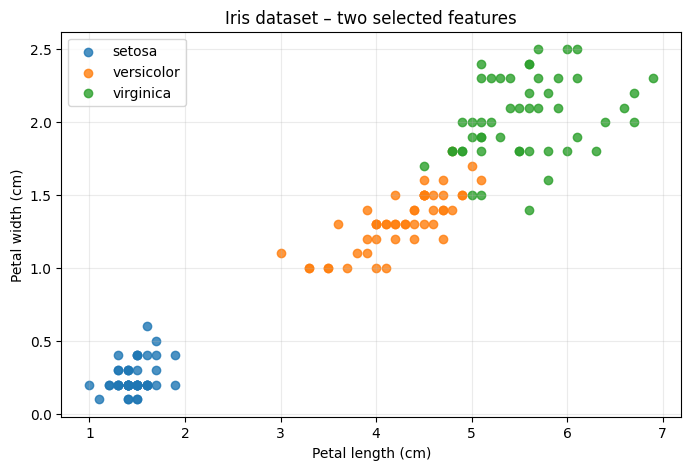

In [2]:
counts = y.value_counts().sort_index()
display(pd.DataFrame({"species": iris.target_names, "count": counts.values}))

plt.figure(figsize=(8, 5))
for class_id, species in enumerate(iris.target_names):
    mask = y == class_id
    plt.scatter(X.loc[mask, "petal length (cm)"],
                X.loc[mask, "petal width (cm)"],
                label=species, alpha=0.8)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris dataset – two selected features")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 3. Train/test split

We hold out 20% for final testing. `stratify=y` preserves class proportions. Scaling is placed inside a pipeline so it is fitted only on training data, avoiding data leakage.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 120
Testing rows: 30


## 4. Why feature scaling matters

KNN uses distance. Imagine comparing customer age (roughly 18–80) with annual income (perhaps 20,000–2,000,000). Without scaling, income can dominate distance because its numeric values are much larger.

Common approaches:
- **Standardization (Z-score):** centers features around 0 and scales by standard deviation.
- **Min-Max scaling:** maps values to a chosen range, often 0 to 1.

We use `StandardScaler` in this notebook.


In [4]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
print("Original training feature standard deviations:")
display(X_train.std().to_frame("std"))
print("Scaled training feature means and standard deviations:")
display(pd.DataFrame({
    "mean": X_scaled.mean(),
    "std": X_scaled.std()
}))


Original training feature standard deviations:


,std
sepal length (cm),0.840926
sepal width (cm),0.448524
petal length (cm),1.768520
petal width (cm),0.762663


Scaled training feature means and standard deviations:


,mean,std
sepal length (cm),-1.369275e-16,1.004193
sepal width (cm),9.992007e-16,1.004193
petal length (cm),1.665335e-17,1.004193
petal width (cm),1.702342e-16,1.004193


## 5. Train your first KNN classifier (K=5, Euclidean distance)

In [5]:
knn5 = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5, metric="euclidean"))
])
knn5.fit(X_train, y_train)
pred = knn5.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("Macro precision:", round(precision_score(y_test, pred, average="macro"), 3))
print("Macro recall:", round(recall_score(y_test, pred, average="macro"), 3))
print("Macro F1:", round(f1_score(y_test, pred, average="macro"), 3))
print(classification_report(y_test, pred, target_names=iris.target_names))


Accuracy: 0.933
Macro precision: 0.944
Macro recall: 0.933
Macro F1: 0.933
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



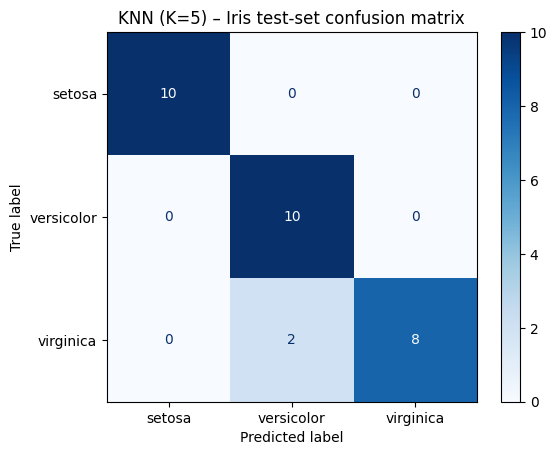

In [6]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=iris.target_names,
    cmap="Blues", values_format="d"
)
plt.title("KNN (K=5) – Iris test-set confusion matrix")
plt.show()


## 6. Experiment with different K values

- Very small K can be sensitive to noise and individual observations.
- Very large K can smooth away local patterns and may underfit.
- There is no universally best K. Select it using validation data.

Odd K values are sometimes used to reduce ties in binary classification, although ties can still occur in multi-class tasks.


In [7]:
k_values = list(range(1, 26, 2))
rows = []

for k in k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, metric="euclidean"))
    ])
    model.fit(X_train, y_train)
    rows.append({
        "K": k,
        "train_accuracy": model.score(X_train, y_train),
        "test_accuracy": model.score(X_test, y_test)
    })

k_results = pd.DataFrame(rows)
display(k_results)


,K,train_accuracy,test_accuracy
0,1,1.000000,0.966667
1,3,0.958333,0.933333
2,5,0.975000,0.933333
3,7,0.975000,0.966667
4,9,0.958333,0.966667
5,11,0.958333,0.966667
6,13,0.958333,0.966667
7,15,0.966667,0.966667
8,17,0.958333,0.966667
9,19,0.941667,0.966667


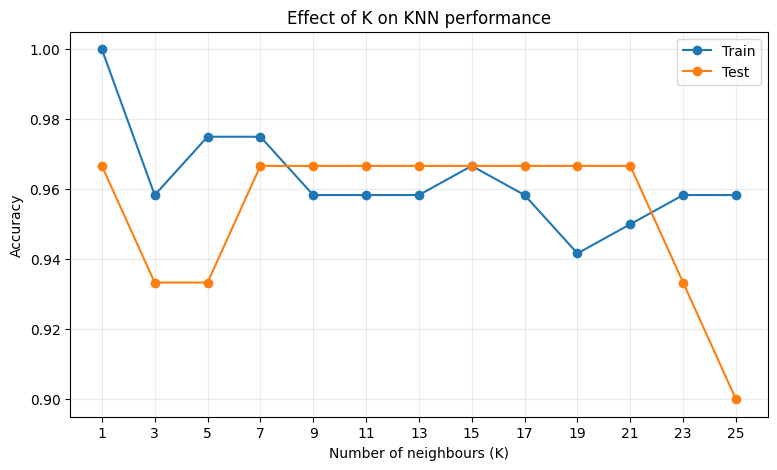

In [8]:
plt.figure(figsize=(9, 5))
plt.plot(k_results["K"], k_results["train_accuracy"], marker="o", label="Train")
plt.plot(k_results["K"], k_results["test_accuracy"], marker="o", label="Test")
plt.xlabel("Number of neighbours (K)")
plt.ylabel("Accuracy")
plt.title("Effect of K on KNN performance")
plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 7. Compare Euclidean and Manhattan distance

**Euclidean (L2):** straight-line distance.

\[d(x,y)=\sqrt{\sum_i (x_i-y_i)^2}\]

**Manhattan (L1):** sum of absolute coordinate differences.

\[d(x,y)=\sum_i |x_i-y_i|\]

A city-grid analogy: Manhattan distance resembles travelling along horizontal and vertical streets; Euclidean distance is the direct straight-line distance. Which works better depends on the data, so compare both.


In [9]:
distance_rows = []
for metric in ["euclidean", "manhattan"]:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=5, metric=metric))
    ])
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    distance_rows.append({
        "metric": metric,
        "accuracy": accuracy_score(y_test, p),
        "macro_precision": precision_score(y_test, p, average="macro"),
        "macro_recall": recall_score(y_test, p, average="macro"),
        "macro_f1": f1_score(y_test, p, average="macro")
    })
display(pd.DataFrame(distance_rows))


,metric,accuracy,macro_precision,macro_recall,macro_f1
0,euclidean,0.933333,0.944444,0.933333,0.93266
1,manhattan,0.933333,0.944444,0.933333,0.93266


## 8. Select K using cross-validation

A single train/test split can depend on which observations happened to be held out. Cross-validation estimates performance across multiple validation folds.

Here, we use 5-fold cross-validation on the training data. The test set remains untouched for the final evaluation.


In [10]:
cv_rows = []
for k in k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, metric="euclidean"))
    ])
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    cv_rows.append({
        "K": k,
        "mean_cv_accuracy": scores.mean(),
        "std_cv_accuracy": scores.std()
    })

cv_results = pd.DataFrame(cv_rows)
display(cv_results.sort_values("mean_cv_accuracy", ascending=False))


,K,mean_cv_accuracy,std_cv_accuracy
2,5,0.966667,0.031180
4,9,0.958333,0.026352
8,17,0.958333,0.026352
7,15,0.958333,0.026352
5,11,0.958333,0.026352
1,3,0.958333,0.037268
3,7,0.958333,0.037268
6,13,0.950000,0.040825
0,1,0.941667,0.042492
9,19,0.941667,0.020412


In [ ]:
plt.figure(figsize=(9, 5))
plt.errorbar(cv_results["K"], cv_results["mean_cv_accuracy"],
             yerr=cv_results["std_cv_accuracy"], marker="o", capsize=4)
plt.xlabel("K")
plt.ylabel("Mean 5-fold CV accuracy")
plt.title("Choosing K with cross-validation")
plt.xticks(k_values)
plt.grid(alpha=0.25)
plt.show()


## 9. Final evaluation of the selected K

K selected by cross-validation: 5
Final test accuracy: 0.933
Final macro F1: 0.933
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



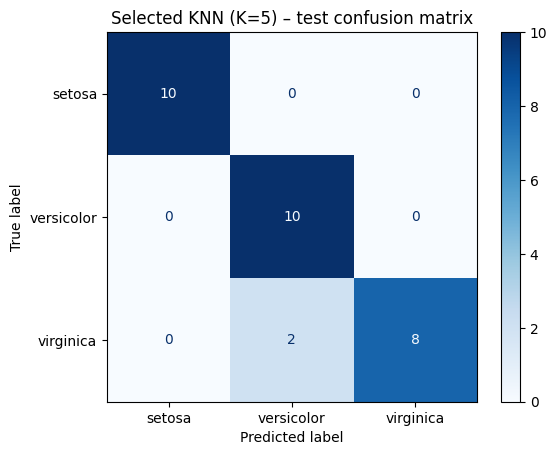

In [11]:
best_k = int(cv_results.loc[cv_results["mean_cv_accuracy"].idxmax(), "K"])
print("K selected by cross-validation:", best_k)

best_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k, metric="euclidean"))
])
best_knn.fit(X_train, y_train)
best_pred = best_knn.predict(X_test)

print("Final test accuracy:", round(accuracy_score(y_test, best_pred), 3))
print("Final macro F1:", round(f1_score(y_test, best_pred, average="macro"), 3))
print(classification_report(y_test, best_pred, target_names=iris.target_names))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=iris.target_names,
    cmap="Blues", values_format="d"
)
plt.title(f"Selected KNN (K={best_k}) – test confusion matrix")
plt.show()


## 10. Optional extension: KNN regression

KNN can also be used for regression. Instead of majority voting, it commonly predicts the average target value of the K nearest observations.

Example: estimate a house price using nearby houses with similar features. This optional demonstration uses the built-in diabetes dataset and a continuous target.


In [12]:
from sklearn.datasets import load_diabetes
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

diabetes = load_diabetes(as_frame=True)
Xr, yr = diabetes.data, diabetes.target
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.20, random_state=42
)

knn_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=5))
])
knn_reg.fit(Xr_train, yr_train)
yr_pred = knn_reg.predict(Xr_test)

print("MAE:", round(mean_absolute_error(yr_test, yr_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(yr_test, yr_pred)), 2))
print("R-squared:", round(r2_score(yr_test, yr_pred), 3))


MAE: 42.78
RMSE: 55.2
R-squared: 0.425


## 11. Business discussion: customer similarity

A retailer wants to predict whether a new customer is likely to respond to a campaign based on historical customer profiles.

Discuss:
1. What customer features could be useful?
2. Why should age, income and purchase count be scaled?
3. What could happen if K=1?
4. What could happen if K is too large?
5. How would you compare Euclidean and Manhattan distance?
6. If missing a likely responder is costly, which metric would you examine?
7. How might prediction latency change as the training dataset grows?

**Operational consideration:** KNN is often called a lazy learner because it stores training examples and performs much of its computation at prediction time. Prediction can become more expensive as the dataset grows.


## 12. Knowledge check

1. What does K represent?
2. What is the difference between Euclidean and Manhattan distance?
3. Why is feature scaling important?
4. What is a risk of K=1?
5. What is a risk of a very large K?
6. How does KNN classification differ from KNN regression?
7. Why use cross-validation to select K?
8. Why should the final test set not be repeatedly used during tuning?

### Suggested answers
1. Number of nearest training observations used for a prediction.
2. Euclidean is straight-line distance; Manhattan sums absolute coordinate differences.
3. Large-scale features can dominate distance calculations.
4. Sensitivity to noise and outliers.
5. Oversmoothing and underfitting.
6. Classification uses a neighbour vote; regression commonly averages neighbour target values.
7. It estimates performance across multiple validation folds.
8. Repeated test-set use leaks information into model selection and can make the final estimate optimistic.
